<a href="https://colab.research.google.com/github/Pruiz2005/Sephora/blob/master/Sephora.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import glob
import os

# Define la ruta donde están tus archivos
path = '/content/drive/MyDrive/Trabajo_Sephora'

# Busca todos los CSV que sigan el patrón 'reviews_*.csv'
all_files = glob.glob(os.path.join(path, "reviews_*.csv"))

# Concatena todos en un solo DataFrame
df_reviews = pd.concat((pd.read_csv(f) for f in all_files), ignore_index=True)

print(f"Total de reseñas cargadas: {len(df_reviews)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total de reseñas cargadas: 285412


In [ ]:
# 1. Seleccionar columnas necesarias
# Ajusta los nombres de las columnas según tu dataset real
cols_to_keep = ['review_text', 'skin_type', 'product_id', 'is_recommended', 'rating']
df = df_reviews[cols_to_keep].copy()

# 2. Eliminar filas donde el texto de la reseña sea nulo
df = df.dropna(subset=['review_text'])

# 3. Tratar valores faltantes en metadatos
# Si el tipo de piel es nulo, podemos poner 'unknown' para no perder la reseña
df['skin_type'] = df['skin_type'].fillna('unknown')

print(f"Registros después de la limpieza inicial: {len(df)}")

Registros después de la limpieza inicial: 285067


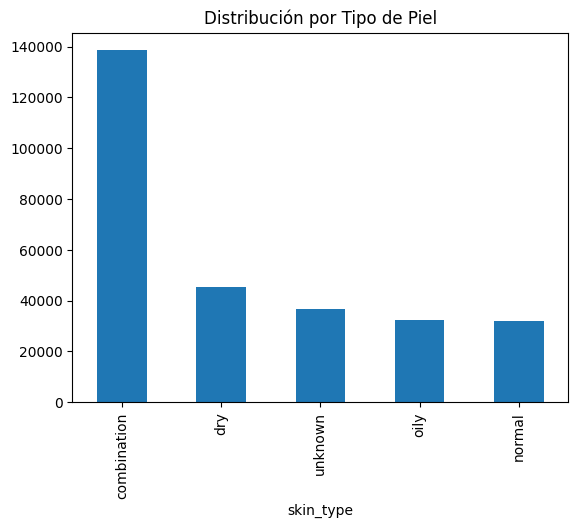

In [ ]:
import matplotlib.pyplot as plt

# Ver cuántas reseñas hay por tipo de piel
df['skin_type'].value_counts().plot(kind='bar', title='Distribución por Tipo de Piel')
plt.show()


In [ ]:
# Ejecuta esto en una celda de Colab
!python -m spacy download en_core_web_sm

import spacy
import pandas as pd

# Cargamos el modelo desactivando componentes que no usaremos (NER y Parser)
# Esto acelera el proceso drásticamente.
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 46.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
def clean_text(doc):
    # Extraemos el lemma, pasamos a minúsculas y filtramos
    tokens = [token.lemma_.lower() for token in doc
              if not token.is_stop and not token.is_punct and token.is_alpha]
    return " ".join(tokens)

In [ ]:
# 1. Preparamos una lista con los textos (asegúrate de que no haya nulos)
texts = df['review_text'].astype(str).tolist()

# 2. Procesamos con nlp.pipe
# batch_size: cuántas reseñas procesa a la vez
# n_process: usa -1 para usar todos los núcleos disponibles en Colab
cleaned_reviews = []

print("Iniciando el procesamiento... esto puede tardar unos minutos.")

for doc in nlp.pipe(texts, batch_size=1000, n_process=-1):
    cleaned_reviews.append(clean_text(doc))

# 3. Guardamos el resultado en una nueva columna
df['cleaned_review'] = cleaned_reviews

print("¡Procesamiento completado!")

Iniciando el procesamiento... esto puede tardar unos minutos.
¡Procesamiento completado!


In [ ]:
cleaned_reviews = '/content/drive/MyDrive/Trabajo_Sephora/reviews_cleaned_ult.npy'

In [ ]:
import pandas as pd

# Definimos la ruta del archivo
ruta_archivo = '/content/drive/MyDrive/Trabajo_Sephora/reviews_cleaned.csv'

# Cargamos los datos
df = pd.read_csv(ruta_archivo)

# Verificamos que se cargó bien
print(f"¡Listo! Se han cargado {len(df)} registros.")
display(df.head())

¡Listo! Se han cargado 285067 registros.


,review_text,skin_type,product_id,is_recommended,rating,cleaned_review
0,I use this with the Nudestix “Citrus Clean Bal...,dry,P504322,1.0,5,use nudestix citrus clean balm melt double cle...
1,I bought this lip mask after reading the revie...,unknown,P420652,0.0,1,buy lip mask read review hype unfortunately me...
2,My review title says it all! I get so excited ...,dry,P420652,1.0,5,review title say excited bed apply lip mask di...
3,I’ve always loved this formula for a long time...,combination,P420652,1.0,5,love formula long time honestly use night time...
4,"If you have dry cracked lips, this is a must h...",combination,P420652,1.0,5,dry crack lip week use learn bedside think lit...


In [ ]:
# Tomamos una reseña al azar del dataset original para comparar
sample_index = 42  # Puedes cambiar este número
original_text = df['review_text'].iloc[sample_index]
processed_text = df['cleaned_review'].iloc[sample_index]

print("--- COMPARATIVA DE PREPROCESAMIENTO ---")
print(f"ORIGINAL:\n{original_text}\n")
print(f"LIMPIO (SpaCy):\n{processed_text}")
print("-" * 40)

# Verificamos si hay palabras vacías que se hayan colado
from collections import Counter
all_words = " ".join(df['cleaned_review'].head(1000)).split()
common_words = Counter(all_words).most_common(10)
print(f"Palabras más frecuentes (deben ser lemmas con significado): {common_words}")

--- COMPARATIVA DE PREPROCESAMIENTO ---
ORIGINAL:
I wanted to love this product so bad because of all the amazing reviews but it honestly makes my lips so disgustingly chapped. I’ve used other lip masks that this hasn’t happened with and went back to try the laniege one again and it gave me chapped lips again :(

LIMPIO (SpaCy):
want love product bad amazing review honestly make lip disgustingly chap lip mask happen go try laniege give chap lip
----------------------------------------
Palabras más frecuentes (deben ser lemmas con significado): [('lip', 1471), ('product', 480), ('love', 379), ('mask', 337), ('feel', 293), ('like', 290), ('smell', 288), ('use', 275), ('dry', 274), ('good', 240)]


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Limitamos a 5000 características para no saturar la memoria
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
# Rellenamos los posibles valores NaN en 'cleaned_review' con una cadena vacía
tfidf_matrix = tfidf_vectorizer.fit_transform(df['cleaned_review'].fillna(''))

print(f"Matriz TF-IDF creada: {tfidf_matrix.shape}")

Matriz TF-IDF creada: (285067, 5000)


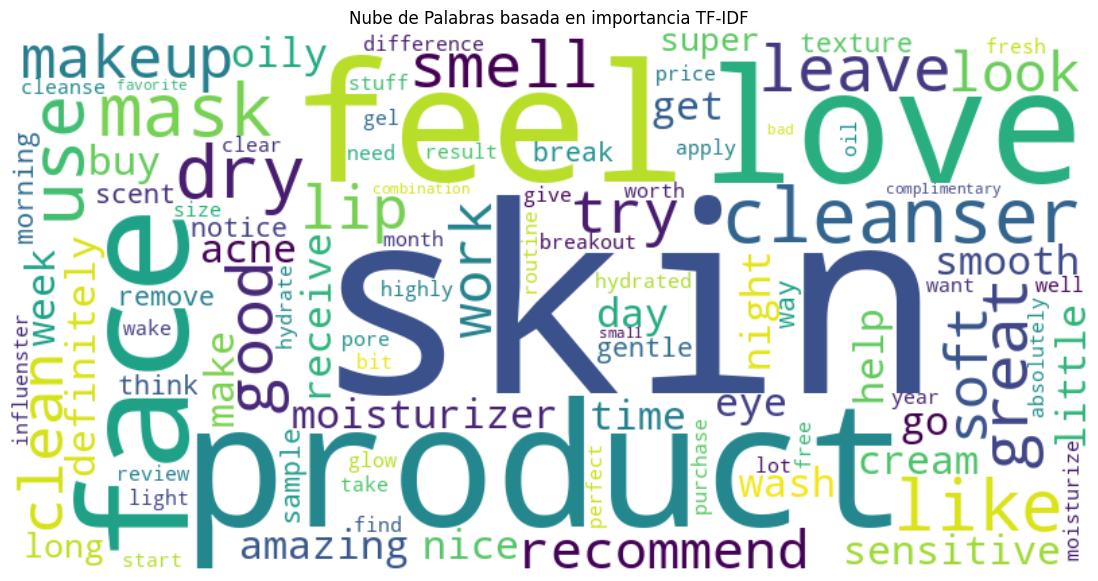

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Get feature names from the TF-IDF vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# Calculate the sum of TF-IDF scores for each feature
sums = tfidf_matrix.sum(axis=0)

# Crear un diccionario de palabras y sus scores
tfidf_scores = dict(zip(feature_names, sums.tolist()[0]))

# Generar la nube de palabras
wordcloud = WordCloud(width=800, height=400,
                      background_color='white',
                      max_words=100).generate_from_frequencies(tfidf_scores)

# Mostrar la imagen
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras basada en importancia TF-IDF')
plt.show()

In [ ]:
import numpy as np
import os
from sentence_transformers import SentenceTransformer

# Initialize the sentence transformer model
# You might need to install sentence-transformers first: !pip install sentence-transformers
model = SentenceTransformer('all-MiniLM-L6-v2') # Or another suitable model

# 1. Aseguramos que el texto esté limpio y sin valores nulos
#    Ahora usamos 'df' en lugar de 'df_reviews' para que los embeddings
#    correspondan a las reseñas limpiadas.
texts = df['cleaned_review'].astype(str).tolist()

print(f"Iniciando proceso para {len(texts)} reseñas...")
print("Estimación: 3-5 horas. El archivo se guardará automáticamente al finalizar.")

# 2. Generamos los Embeddings
# Usamos un batch_size de 64 para ir rápido, si da error de memoria, bájalo a 32.
embeddings_full = model.encode(texts, batch_size=64, show_progress_bar=True)

# 3. Guardar en Drive inmediatamente
ruta_drive = '/content/drive/MyDrive/Trabajo_Sephora/embeddings_for_cleaned_df.npy' # New filename for cleaned df embeddings

# Crear la carpeta si no existe
os.makedirs(os.path.dirname(ruta_drive), exist_ok=True)

# Guardar matriz
np.save(ruta_drive, embeddings_full)

print(f"¡TRABAJO COMPLETADO! Archivo guardado en: {ruta_drive}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Iniciando proceso para 285067 reseñas...
Estimación: 3-5 horas. El archivo se guardará automáticamente al finalizar.


Batches:   0%|          | 0/4455 [00:00<?, ?it/s]

¡TRABAJO COMPLETADO! Archivo guardado en: /content/drive/MyDrive/Trabajo_Sephora/embeddings_for_cleaned_df.npy


Calculando el Método del Codo... Esto puede tardar unos minutos con tantos datos.


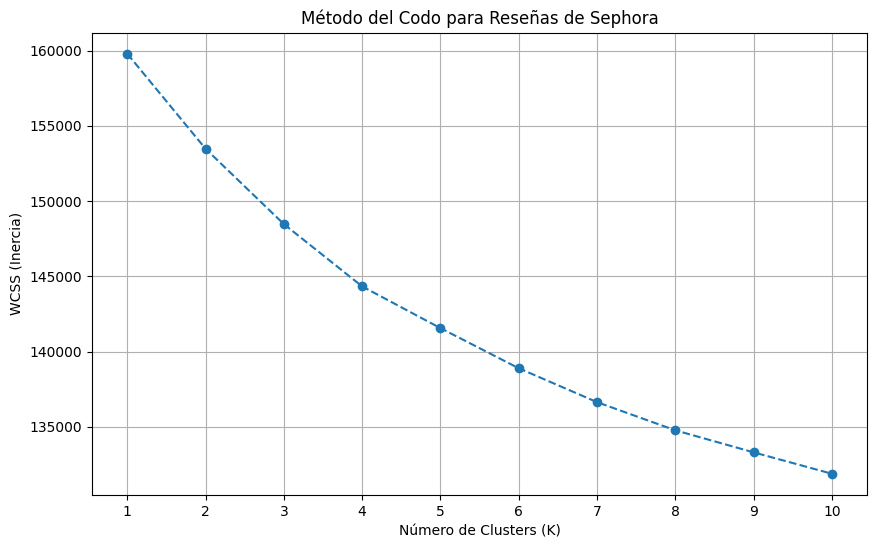

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Cargamos los datos (asegúrate de haber ejecutado la carga del archivo .npy antes)
# X = embeddings_full

print("Calculando el Método del Codo... Esto puede tardar unos minutos con tantos datos.")

wcss = []
# Probamos a dividir las reseñas en grupos del 1 al 10
for i in range(1, 11):
    # Usamos n_init=10 para asegurar buenos resultados
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(embeddings_full) # Usamos tu matriz gigante
    wcss.append(kmeans.inertia_)

# 2. Dibujamos el gráfico
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Método del Codo para Reseñas de Sephora')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS (Inercia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
print(f"Filas en el DataFrame (df): {len(df)}")
print(f"Filas en la matriz de Embeddings: {len(embeddings_full)}")

import numpy as np

# Definir la ruta
ruta_drive_embeddings = '/content/drive/MyDrive/Trabajo_Sephora/embeddings_Palo.npy'

# Guardar la matriz
np.save(ruta_drive_embeddings, embeddings_full)
print(f"Embeddings guardados en: {ruta_drive_embeddings}")

# Definir la ruta
ruta_reviews = '/content/drive/MyDrive/Trabajo_Sephora/reviews_cleaned_palo.npy'

# Guardar la matriz
np.save(ruta_reviews, df)


Filas en el DataFrame (df): 285067
Filas en la matriz de Embeddings: 285067
Embeddings guardados en: /content/drive/MyDrive/Trabajo_Sephora/embeddings_Palo.npy


In [ ]:
# 1. Sincronizamos: Nos aseguramos de que df tenga el mismo tamaño que los embeddings
# Si borraste nulos después de crear los embeddings, esto fallará.
# Asumiendo que embeddings_full tiene 32,117 filas:
df = df.iloc[:len(embeddings_sincronizados)].copy()

# 2. Definimos el modelo de nuevo desde cero para limpiar cualquier config previa
k_final = 5
kmeans_final = KMeans(n_clusters=k_final, init='k-means++', random_state=42, n_init=10)

# 3. Ejecutamos sobre la matriz de embeddings
cluster_labels = kmeans_final.fit_predict(embeddings_sincronizados)

# 4. Asignamos al DataFrame
df['cluster'] = cluster_labels

print(f"¡Logrado! Hemos organizado {len(df)} reseñas en {k_final} grupos.")

KeyboardInterrupt: 